# Arsenal 2–0 Everton — match analysis (working notebook)

Premier League 2026/27, 24 October 2026. This is the step-by-step working notebook: it downloads the event data from WhoScored with [`soccerdata`](https://github.com/probberechts/soccerdata), then builds each chart one at a time with [`mplsoccer`](https://mplsoccer.readthedocs.io/).

The finished, tidied-up version of these charts — rewritten as reusable functions and combined into a one-page report — is in **`Match_Report.ipynb`**.

**Pitch coordinates:** Opta style, 0–100 on both axes, with each team attacking left → right (x = 100 is the opponent's goal). Everton's events are flipped (`100 - x`, `100 - y`) whenever both teams are drawn on one pitch.

## 1. Setup and data

Install the packages, load the WhoScored scraper and pull the event data for this match. The events are saved to `arsenal_everton.csv`, so after the first run you can start from the *Load the saved events* cell.

In [ ]:
%pip install soccerdata mplsoccer

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from mplsoccer import Pitch, VerticalPitch
import soccerdata as sd
import ast
import numpy as np
from matplotlib.patches import Rectangle

[11/04/26 16:09:07] INFO     No custom team name replacements found. You can configure these in       _config.py:91
                             C:\Users\samj7\soccerdata\config\teamname_replacements.json.                          

                    INFO     No custom league dict found. You can configure additional leagues in    _config.py:189
                             C:\Users\samj7\soccerdata\config\league_dict.json.                                    

In [3]:
ws = sd.WhoScored(leagues="ENG-Premier League", seasons="2627", headless=False)

                    INFO     Saving cached data to C:\Users\samj7\soccerdata\data\WhoScored          _common.py:300

In [4]:
schedule = ws.read_schedule().reset_index()

[11/04/26 16:09:25] INFO     Retrieving calendar for ENG-Premier League 2627                       whoscored.py:368

[11/04/26 16:09:38] INFO     [1/10] Retrieving fixtures for ENG-Premier League 2627                whoscored.py:399

[11/04/26 16:09:46] INFO     [2/10] Retrieving fixtures for ENG-Premier League 2627                whoscored.py:399

[11/04/26 16:09:56] INFO     [3/10] Retrieving fixtures for ENG-Premier League 2627                whoscored.py:399

[11/04/26 16:10:05] INFO     [4/10] Retrieving fixtures for ENG-Premier League 2627                whoscored.py:399

[11/04/26 16:10:13] INFO     [5/10] Retrieving fixtures for ENG-Premier League 2627                whoscored.py:399

[11/04/26 16:10:22] INFO     [6/10] Retrieving fixtures for ENG-Premier League 2627                whoscored.py:399

[11/04/26 16:10:29] INFO     [7/10] Retrieving fixtures for ENG-Premier League 2627                whoscored.py:399

[11/04/26 16:10:39] INFO     [8/10] Retrieving fixtures for ENG-Premier League 2627                whoscored.py:399

[11/04/26 16:10:51] INFO     [9/10] Retrieving fixtures for ENG-Premier League 2627                whoscored.py:399

[11/04/26 16:10:59] INFO     [10/10] Retrieving fixtures for ENG-Premier League 2627               whoscored.py:399

In [5]:
game = schedule[
    (schedule["home_team"] == "Arsenal") & (schedule["away_team"] == "Everton")
]
game

,league,season,game,stage_id,game_id,status,start_time,home_team_id,home_team,home_yellow_cards,...,period,extra_result_field,home_extratime_score,away_extratime_score,home_penalty_score,away_penalty_score,started_at_utc,first_half_ended_at_utc,second_half_started_at_utc,stage
71,ENG-Premier League,2627,2026-10-24 Arsenal-Everton,25544,1983616,6,2026-10-24T15:00:00,13,Arsenal,1,...,7,None,None,None,None,None,2026-10-24T14:00:31Z,2026-10-24T14:47:43Z,2026-10-24T15:03:18Z,None


In [6]:
game_id = int(game["game_id"].iloc[0])

events = ws.read_events(match_id=game_id).reset_index()
events.to_csv("arsenal_everton.csv", index=False)
events.shape

[11/04/26 16:11:20] INFO     Retrieving calendar for ENG-Premier League 2627                       whoscored.py:368

[11/04/26 16:11:32] INFO     [1/10] Retrieving fixtures for ENG-Premier League 2627                whoscored.py:399

[11/04/26 16:11:39] INFO     [2/10] Retrieving fixtures for ENG-Premier League 2627                whoscored.py:399

[11/04/26 16:11:48] INFO     [3/10] Retrieving fixtures for ENG-Premier League 2627                whoscored.py:399

[11/04/26 16:11:56] INFO     [4/10] Retrieving fixtures for ENG-Premier League 2627                whoscored.py:399

[11/04/26 16:12:06] INFO     [5/10] Retrieving fixtures for ENG-Premier League 2627                whoscored.py:399

... (3 outputs left out)

[11/04/26 16:12:44] INFO     [9/10] Retrieving fixtures for ENG-Premier League 2627                whoscored.py:399

[11/04/26 16:12:51] INFO     [10/10] Retrieving fixtures for ENG-Premier League 2627               whoscored.py:399

[11/04/26 16:12:59] INFO     [1/1] Retrieving game with id=1983616                                 whoscored.py:691

(1502, 30)

### Load the saved events

In [7]:
events = pd.read_csv("arsenal_everton.csv")
events[["minute", "team", "player", "type", "outcome_type", "x", "y", "end_x", "end_y"]].head(20)

,minute,team,player,type,outcome_type,x,y,end_x,end_y
0,0,Arsenal,NaN,Start,Successful,0.0,0.0,NaN,NaN
1,0,Everton,NaN,Start,Successful,0.0,0.0,NaN,NaN
2,0,Everton,James Garner,Pass,Successful,50.0,50.0,25.1,58.2
3,0,Everton,Jordan Pickford,Pass,Unsuccessful,25.1,58.2,79.4,13.5
4,0,Arsenal,Gabriel Magalhães,Pass,Successful,25.5,85.6,38.0,82.0
5,0,Arsenal,Mikel Merino,Dispossessed,Successful,35.2,85.0,NaN,NaN
6,0,Everton,Harrison Armstrong,Tackle,Unsuccessful,64.8,15.0,NaN,NaN
7,0,Arsenal,Mikel Merino,BallTouch,Successful,34.2,89.4,NaN,NaN
8,0,Everton,Harrison Armstrong,BallTouch,Unsuccessful,68.9,7.9,NaN,NaN
9,0,Arsenal,Eberechi Eze,BallRecovery,Successful,35.4,93.3,NaN,NaN


In [9]:
print(events["type"].value_counts().to_string())

type
Pass               970
BallRecovery        65
BallTouch           61
Aerial              50
Foul                48
Clearance           47
Tackle              31
TakeOn              31
CornerAwarded       30
Dispossessed        20
SavedShot           17
Save                17
KeeperPickup        15
BlockedPass         14
Challenge           13
Interception        12
MissedShots          9
SubstitutionOff      8
SubstitutionOn       8
Card                 6
End                  6
Start                4
Punch                4
Error                3
Goal                 2
KeeperSweeper        2
FormationChange      2
FormationSet         2
OffsideGiven         1
OffsidePass          1
OffsideProvoked      1
ShieldBallOpp        1
Claim                1


### Notes: key columns and filters

| What | How |
|---|---|
| Pitch type | `"opta"` |
| Start position | `x`, `y` |
| End position of a pass | `end_x`, `end_y` |
| Only passes | `events["type"] == "Pass"` |
| Successful passes | `passes["outcome_type"] == "Successful"` |
| Only shots | `events["is_shot"] == True` |
| Goals | `events["is_goal"] == True` |
| Shots by xG | not in this data |
| Who received the pass | not given directly — guessed from the next event (`shift(-1)`) |
| First substitution | `events[(events["type"] == "SubstitutionOn") & (events["team"] == "Arsenal")]["minute"].min()` |
| Label offset "up" | `y + 4` |

## 2. Shot maps

In [10]:
shots_taken = events[events["is_shot"] == True]
arsenal_shots = shots_taken[shots_taken["team"] == "Arsenal"]
everton_shots = shots_taken[shots_taken["team"] == "Everton"]
arsenal_goals = arsenal_shots[arsenal_shots["is_goal"] == True]
len(arsenal_goals)

everton_shots_flipped = everton_shots.copy()
everton_shots_flipped["x"] = 100 - everton_shots_flipped["x"]
everton_shots_flipped["y"] = 100 - everton_shots_flipped["y"]


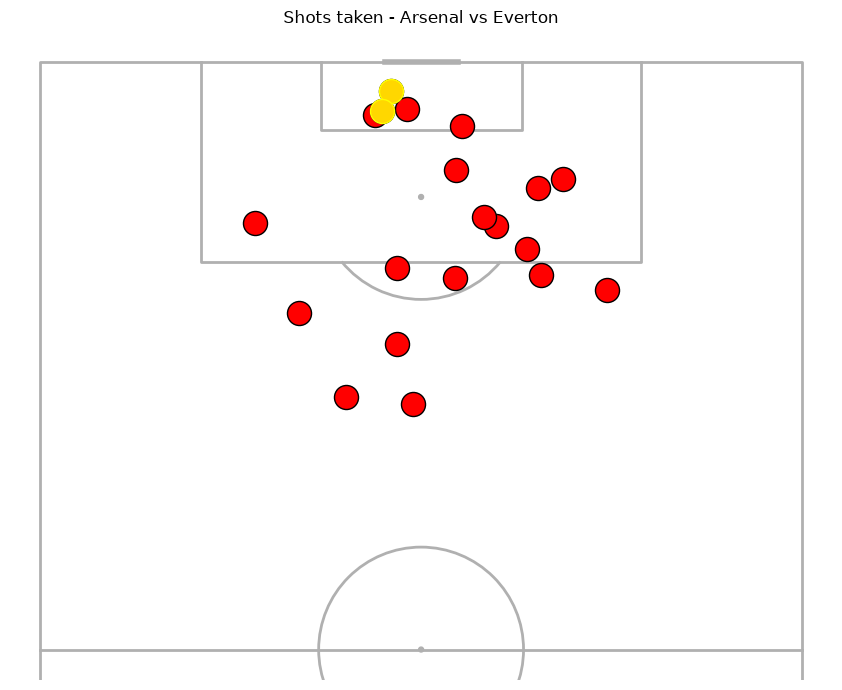

In [12]:
pitch = VerticalPitch(pitch_type="opta", half=True)
fig, ax = pitch.draw(figsize=(10, 7))

pitch.scatter(arsenal_shots["x"], arsenal_shots["y"], ax=ax, s=300, color="red", edgecolor="black")
pitch.scatter(arsenal_goals["x"], arsenal_goals["y"], ax=ax, s=300, color="gold", edgecolor="yellow")

ax.set_title("Shots taken - Arsenal vs Everton")

plt.show()

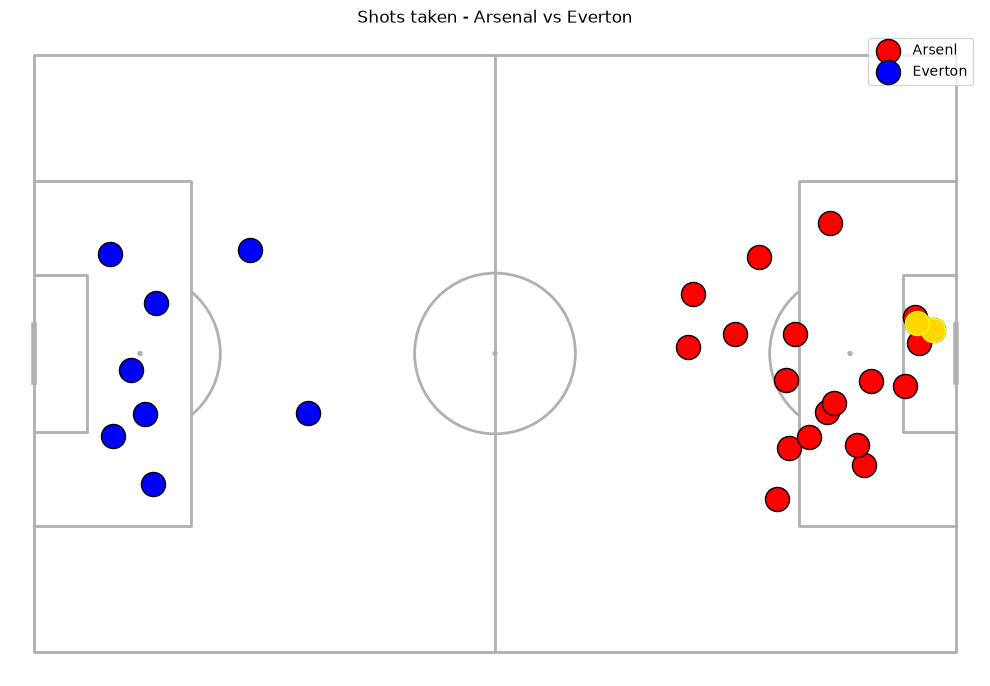

In [ ]:
pitch = Pitch(pitch_type="opta")
fig, ax = pitch.draw(figsize=(10, 7))

pitch.scatter(arsenal_shots["x"], arsenal_shots["y"], ax=ax, s=300, color="red", edgecolor="black", label="Arsenal")
pitch.scatter(everton_shots_flipped["x"], everton_shots_flipped["y"], ax=ax, s=300, color="blue", edgecolor="black", label="Everton")
pitch.scatter(arsenal_goals["x"], arsenal_goals["y"], ax=ax, s=300, color="gold", edgecolor="yellow")

ax.set_title("Shots taken - Arsenal vs Everton")
ax.legend()

plt.show()

## 3. Average positions and passing network

Average position of each Arsenal starter (completed passes before the first substitution), sized by number of completed passes.

In [14]:
arsenal_passes = events[(events["type"] == "Pass") & (events["team"] == "Arsenal")]
len(arsenal_passes)
a_completed = arsenal_passes[arsenal_passes["outcome_type"] == "Successful"]
len(a_completed)

a_subs = events[(events["type"] == "SubstitutionOn") & (events["team"] == "Arsenal")]
a_subs
first_sub = a_subs["minute"].min()
first_sub

starters = a_completed[a_completed["minute"] < first_sub]
starters

avg = starters.groupby("player").agg(
    x = ("x", "mean"),
    y = ("y", "mean"),
    n = ("x", "size")
).sort_values("n", ascending=False)

In [16]:
avg

,x,y,n
player,,,
Martin Ødegaard,56.828814,35.718644,59
Declan Rice,57.082692,46.109615,52
Myles Lewis-Skelly,58.735714,74.066667,42
Gabriel Magalhães,39.207895,71.902632,38
Ben White,64.381818,10.839394,33
Ezri Konsa,33.803704,28.059259,27
Eberechi Eze,66.295652,79.269565,23
Mikel Merino,54.560000,61.290000,20
David Raya,13.288235,50.276471,17


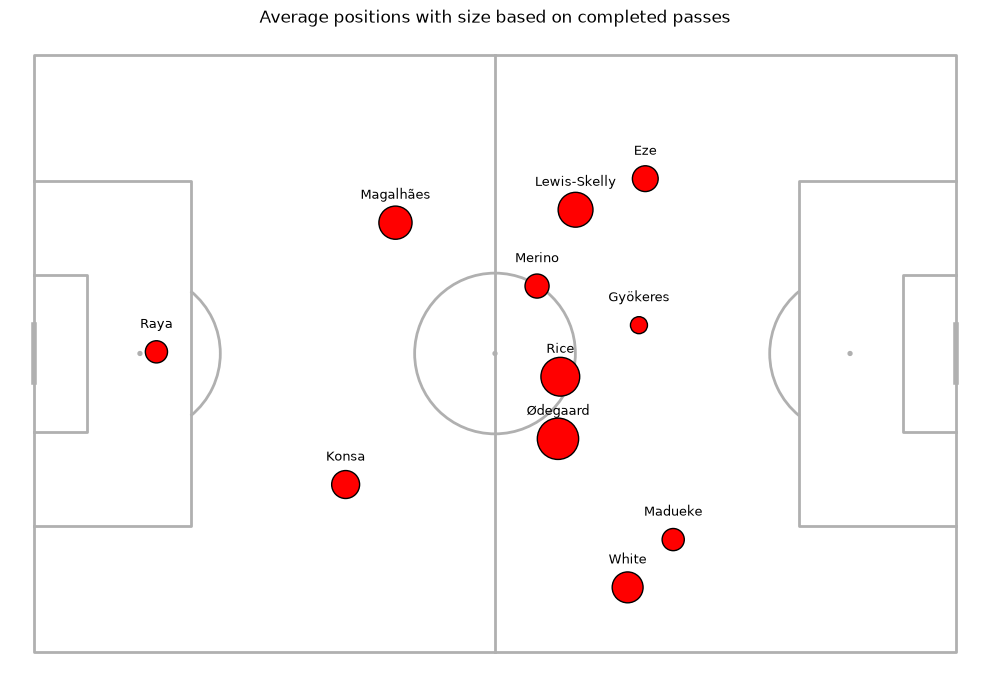

In [17]:
pitch = Pitch(pitch_type="opta")
fig, ax = pitch.draw(figsize=(10,7))

pitch.scatter(avg["x"], avg["y"], ax=ax, s=avg["n"] * 15, color="red", edgecolor="black")

for player, pos in avg.iterrows():
    pitch.annotate(player.split()[-1], xy=(pos["x"], pos["y"] + 4), ax=ax, ha="center", fontsize=9)

ax.set_title("Average positions with size based on completed passes")

plt.show()


If you filter to passes and then `shift(-1)`, the next row's player is (usually) the player who received the pass — that's how the passing network links players together.

In [20]:
events["next_player"] = events["player"].shift(-1)
events["next_team"] = events["team"].shift(-1)

# re-filter so the passes carry the new columns
arsenal_passes = events[(events["type"] == "Pass") & (events["team"] == "Arsenal")]
a_completed = arsenal_passes[arsenal_passes["outcome_type"] == "Successful"]
starters = a_completed[a_completed["minute"] < first_sub]

# passes that reached a teammate, counted per passer -> receiver pair (3+ only)
link = starters[starters["next_team"] == "Arsenal"]
pairs = link.groupby(["player", "next_player"]).size().reset_index(name="count")
pairs = pairs[pairs["count"] >= 3]

In [22]:
events[['player', 'next_player', 'team', 'next_team']].head(10)

,player,next_player,team,next_team
0,NaN,NaN,Arsenal,Everton
1,NaN,James Garner,Everton,Everton
2,James Garner,Jordan Pickford,Everton,Everton
3,Jordan Pickford,Gabriel Magalhães,Everton,Arsenal
4,Gabriel Magalhães,Mikel Merino,Arsenal,Arsenal
5,Mikel Merino,Harrison Armstrong,Arsenal,Everton
6,Harrison Armstrong,Mikel Merino,Everton,Arsenal
7,Mikel Merino,Harrison Armstrong,Arsenal,Everton
8,Harrison Armstrong,Eberechi Eze,Everton,Arsenal
9,Eberechi Eze,Eberechi Eze,Arsenal,Arsenal


In [23]:
pairs["x_start"] = pairs["player"].map(avg["x"])
pairs["y_start"] = pairs["player"].map(avg["y"])
pairs["x_end"] = pairs["next_player"].map(avg["x"])
pairs["y_end"] = pairs["next_player"].map(avg["y"])
pairs["x_arrow"] = pairs["x_start"] + 0.6 * (pairs["x_end"] - pairs["x_start"])
pairs["y_arrow"] = pairs["y_start"] + 0.6 * (pairs["y_end"] - pairs["y_start"])

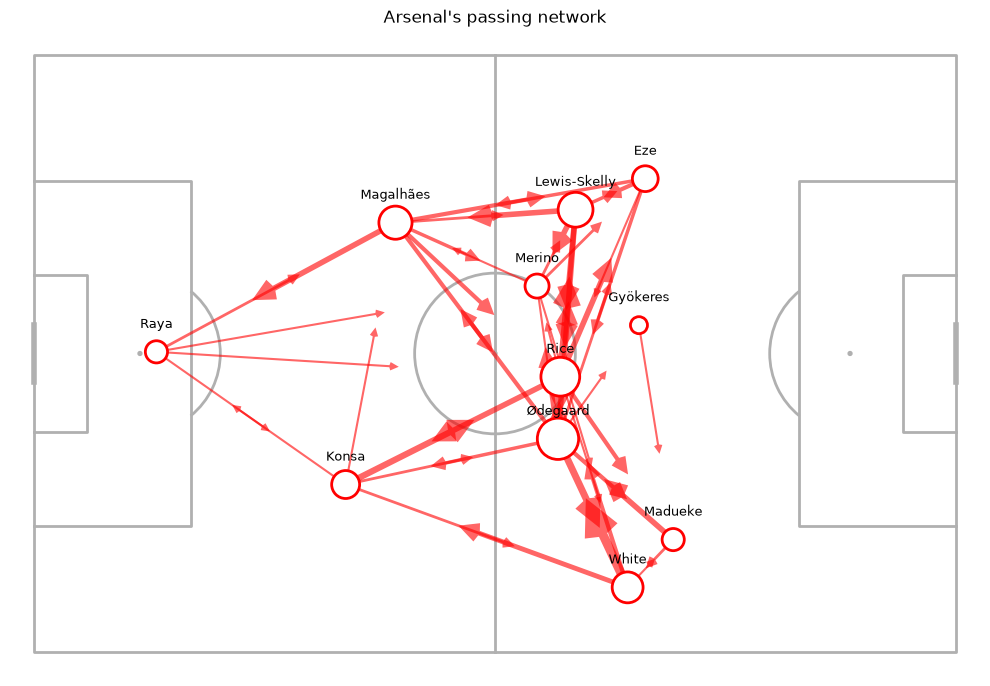

In [24]:
pitch = Pitch(pitch_type="opta")
fig, ax = pitch.draw(figsize= (10, 7))

for _, row in pairs.iterrows():
    pitch.arrows(row["x_start"], row["y_start"], row["x_arrow"], row["y_arrow"],
                 width=row["count"] * 0.5, headwidth=4, headlength=4,
                 color="red", alpha=0.6, ax=ax, zorder=1)

pitch.scatter(avg["x"], avg["y"], s=avg["n"] * 15, color="white",
              edgecolors="red", linewidth=2, ax=ax, zorder=2)

for player, pos in avg.iterrows():
    pitch.annotate(player.split()[-1], xy=(pos["x"], pos["y"] + 4), ax=ax, ha="center", fontsize=9)

ax.set_title("Arsenal's passing network")

plt.show()

## 4. Where passes ended

The pitch is split into a 6 × 5 grid and each box is coloured by the share of completed passes that ended there.

In [33]:
ends = a_completed["end_x"]

defensive = (ends < 33.3).sum()
middle = ((ends >= 33.3) & (ends < 66.7)).sum()
final = (ends >= 66.7).sum()

key_passes = arsenal_passes[arsenal_passes["qualifiers"].str.contains("KeyPass")]
len(key_passes)
chance_passes = arsenal_passes[arsenal_passes["qualifiers"].str.contains("KeyPass|Assist")]

a_stats = pitch.bin_statistic(a_completed["end_x"], a_completed["end_y"], statistic="count", bins=(6, 5), normalize=True)

kp_stats = pitch.bin_statistic(key_passes["x"], key_passes["y"], statistic="count", bins=(6, 5))

In [ ]:
labels = []
for text in events["qualifiers"]:
    for item in ast.literal_eval(text):
        labels.append(item["type"]["displayName"])

print(pd.Series(labels).value_counts().head(25).to_string())

In [ ]:
counts = pd.Series(labels).value_counts()
counts[counts.index.str.contains("Pass")] 

PassEndX    1020
PassEndY    1020
HeadPass      33
KeyPass       24
Name: count, dtype: int64

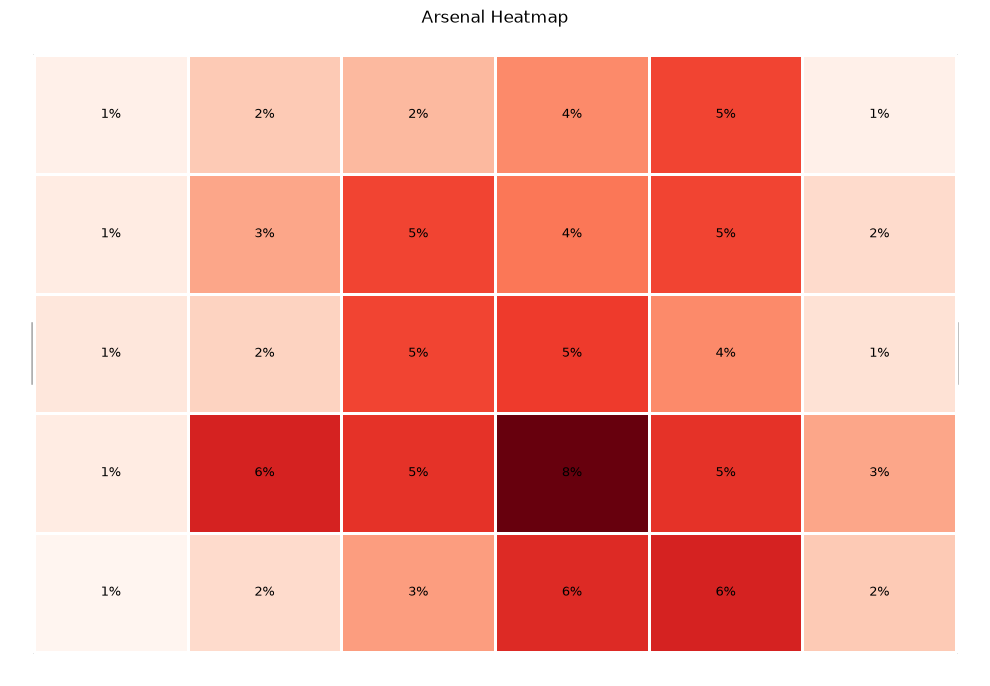

In [26]:
pitch = Pitch(pitch_type="opta")
fig, ax = pitch.draw(figsize=(10, 7))

pitch.heatmap(a_stats, ax=ax, cmap="Reds", edgecolors="white")
pitch.label_heatmap(a_stats, ax=ax, str_format="{:.0%}", ha="center", va="center", fontsize=9)

ax.set_title(" Arsenal Heatmap ")
plt.show()

In [31]:
Passes_ttl = events[events["type"] == "Pass"]
len(Passes_ttl)
e_passes = events[(events["type"] == "Pass") & (events["team"] == "Everton")]
len(e_passes)
e_passes.columns
e_completed = e_passes[e_passes["outcome_type"] == "Successful"]
len(e_completed)
both = [len(e_passes), len(e_completed)]
both

e_ends = e_completed["end_x"]

e_defensive = (e_ends < 33.3).sum()
e_middle = ((e_ends >= 33.3) & (e_ends <= 66.7)).sum()
e_final = (e_ends > 66.7).sum()

e_stats = pitch.bin_statistic(e_completed["end_x"], e_completed["end_y"], statistic="count", bins=(6, 5), normalize=True)

e_key_passes = e_passes[e_passes["qualifiers"].str.contains("KeyPass")]
len(e_key_passes)

e_kp_stats = pitch.bin_statistic(e_key_passes["x"], e_key_passes["y"], statistic="count", bins=(6, 5))

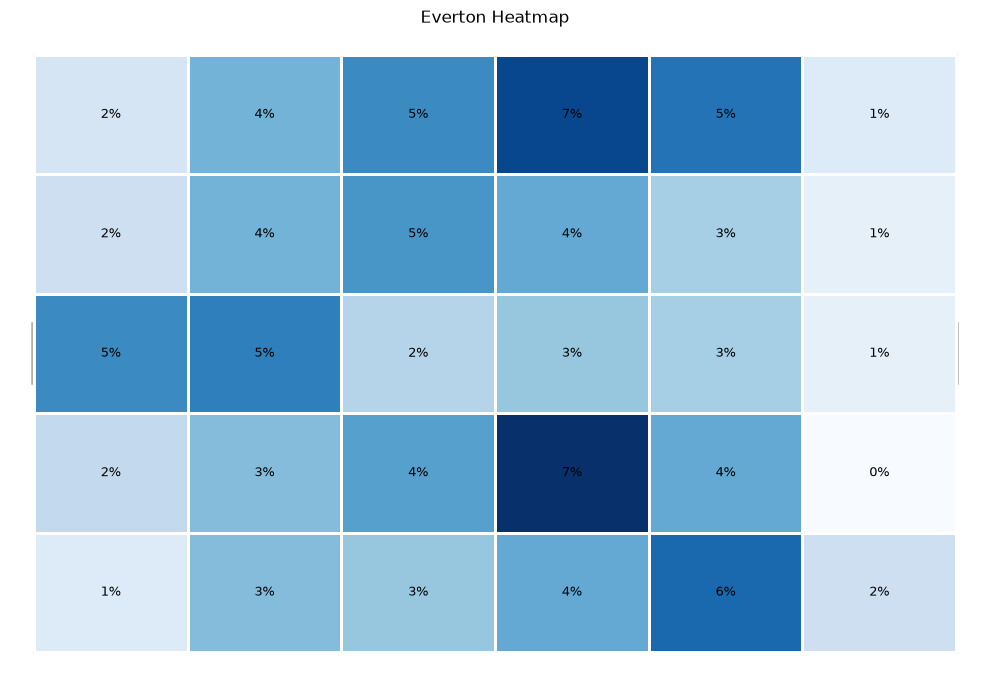

In [28]:
pitch = Pitch(pitch_type="opta")
fig, ax = pitch.draw(figsize=(10, 7))

pitch.heatmap(e_stats, ax=ax, cmap="Blues", edgecolor="white")
pitch.label_heatmap(e_stats, ax=ax, str_format="{:.0%}", ha="center", va="center", fontsize=9)

ax.set_title(" Everton Heatmap ")
plt.show()


## 5. Pass density and chance creation

Key passes are passes that led directly to a shot; the heatmap shows where they were played from.

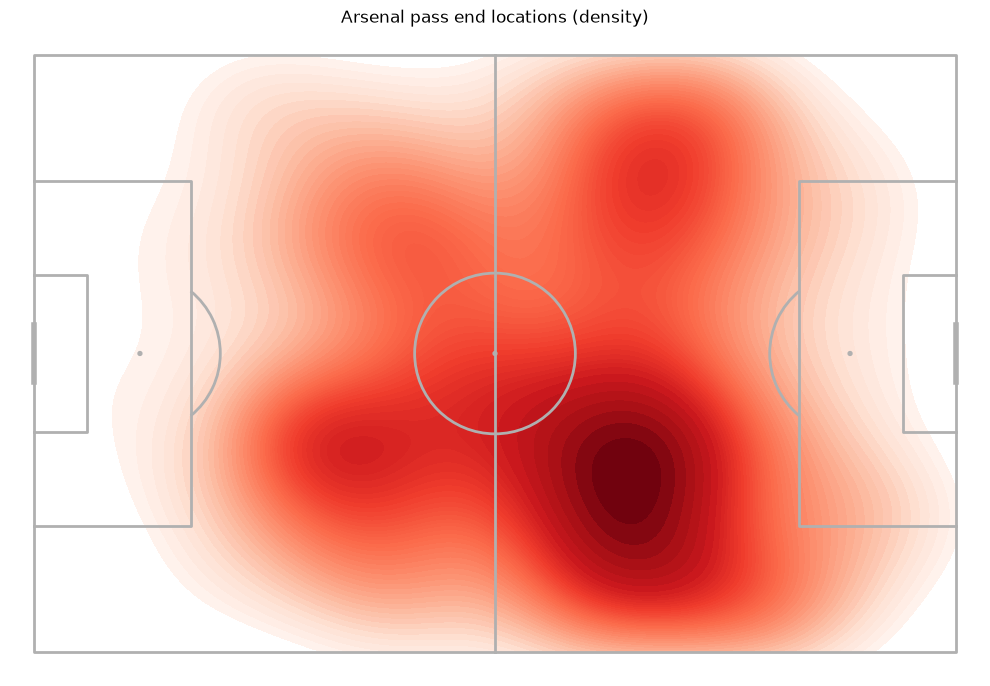

In [30]:
pitch = Pitch(pitch_type="opta", line_zorder=2)
fig, ax = pitch.draw(figsize=(10, 7))

pitch.kdeplot(a_completed["end_x"], a_completed["end_y"], ax=ax,
              fill=True, levels=50, cmap="Reds", thresh=0.05)

ax.set_title("Arsenal pass end locations (density)")
plt.show()

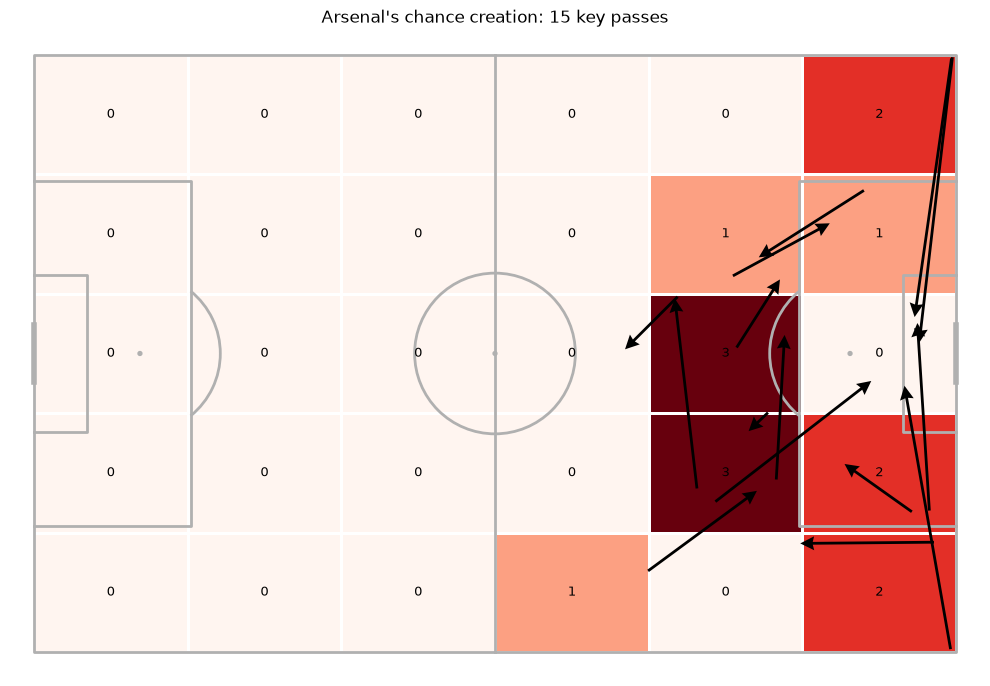

In [34]:
pitch = Pitch(pitch_type="opta", line_zorder=2)
fig, ax = pitch.draw(figsize=(10, 7))

pitch.heatmap(kp_stats, ax=ax, cmap="Reds", edgecolor="white")
pitch.label_heatmap(kp_stats, ax=ax, str_format="{:.0f}",
                    ha="center", va="center", fontsize=9)

pitch.arrows(key_passes["x"], key_passes["y"],
             key_passes["end_x"], key_passes["end_y"],
             ax=ax, width=2, headwidth=5, color="black", zorder=3)

ax.set_title(f"Arsenal's chance creation: {len(key_passes)} key passes")
plt.show()

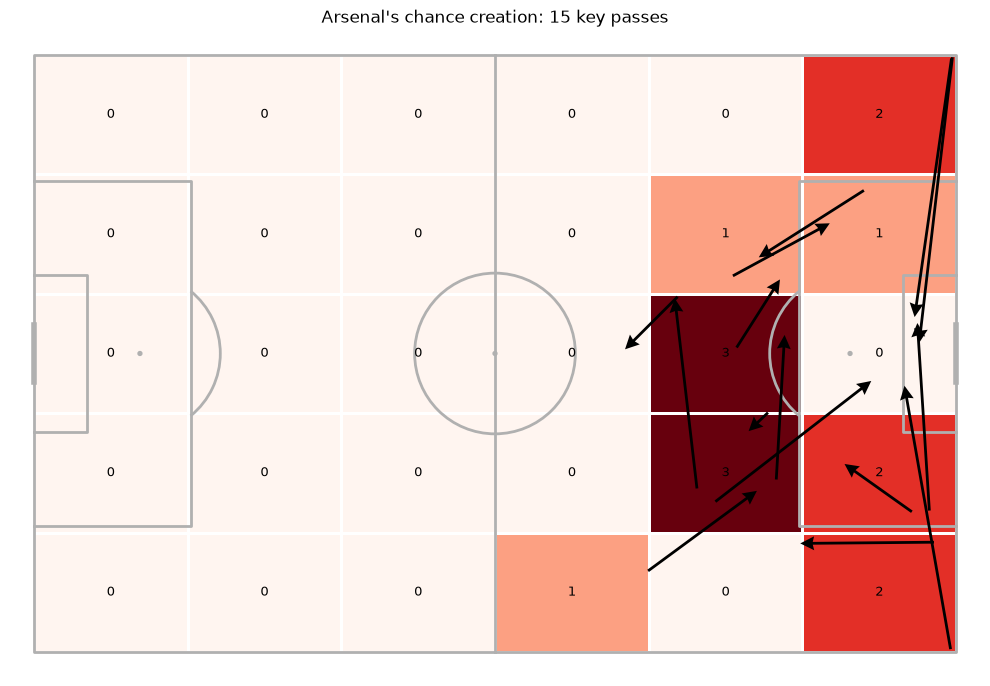

In [36]:
pitch = Pitch(pitch_type="opta", line_zorder=2)
fig, ax = pitch.draw(figsize=(10, 7))

pitch.heatmap(kp_stats, ax=ax, cmap="Reds", edgecolor="white")
pitch.label_heatmap(kp_stats, ax=ax, str_format="{:.0f}",
                    ha="center", va="center", fontsize=9)

pitch.arrows(chance_passes["x"], chance_passes["y"],
             chance_passes["end_x"], chance_passes["end_y"],
             ax=ax, width=2, headwidth=5, color="black", zorder=3)

ax.set_title(f"Arsenal's chance creation: {len(chance_passes)} key passes and assists")
plt.show()

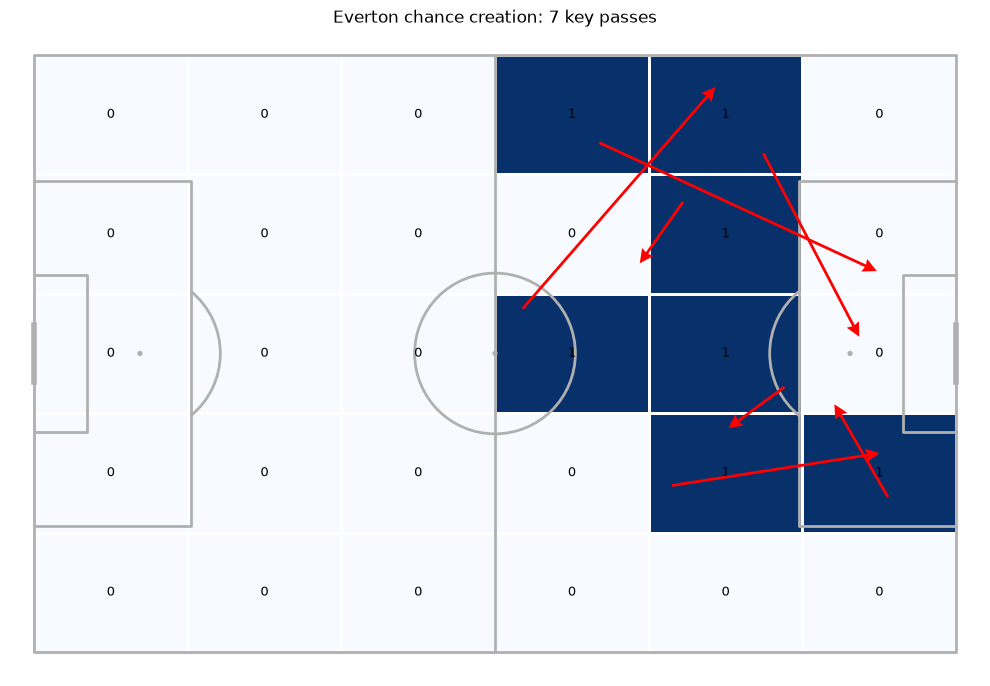

In [32]:
pitch = Pitch(pitch_type="opta", line_zorder=2)
fig, ax = pitch.draw(figsize=(10, 7))

pitch.heatmap(e_kp_stats, ax=ax, cmap="Blues", edgecolor="white")
pitch.label_heatmap(e_kp_stats, ax=ax, str_format="{:.0f}",
                    ha="center", va="center", fontsize=9)

pitch.arrows(e_key_passes["x"], e_key_passes["y"],
             e_key_passes["end_x"], e_key_passes["end_y"],
             ax=ax, width=2, headwidth=5, color="red", zorder=3)

ax.set_title(f"Everton chance creation: {len(e_key_passes)} key passes")
plt.show()

Shots and key passes — `[Arsenal shots, Arsenal key passes, Everton shots, Everton key passes]`:

In [37]:
numbers = [len(arsenal_shots), len(key_passes), len(everton_shots), len(e_key_passes)]
numbers

[20, 15, 8, 7]

In [38]:
assists = arsenal_passes[arsenal_passes["qualifiers"].str.contains("Assist")]
len(assists)

15

## 6. Defensive actions

In [40]:
events["type"].unique()

<StringArray>
[          'Start',            'Pass',    'Dispossessed',          'Tackle',
       'BallTouch',    'BallRecovery',     'BlockedPass',            'Foul',
       'Clearance',       'SavedShot',            'Save',          'TakeOn',
    'KeeperPickup',   'CornerAwarded',          'Aerial',           'Error',
            'Goal',       'Challenge',    'Interception',           'Punch',
     'MissedShots',    'OffsideGiven',     'OffsidePass', 'OffsideProvoked',
   'ShieldBallOpp',   'KeeperSweeper',            'Card',             'End',
           'Claim', 'SubstitutionOff',  'SubstitutionOn', 'FormationChange',
    'FormationSet']
Length: 33, dtype: str

In [41]:
def_types = ["Clearance", "BallRecovery", "BlockedPass", "Interception", "Tackle", "Aerial"]          # the defending event types you found

e_def_actions = events[(events["team"] == "Everton") & (events["type"].isin(def_types))]
len(e_def_actions)

125

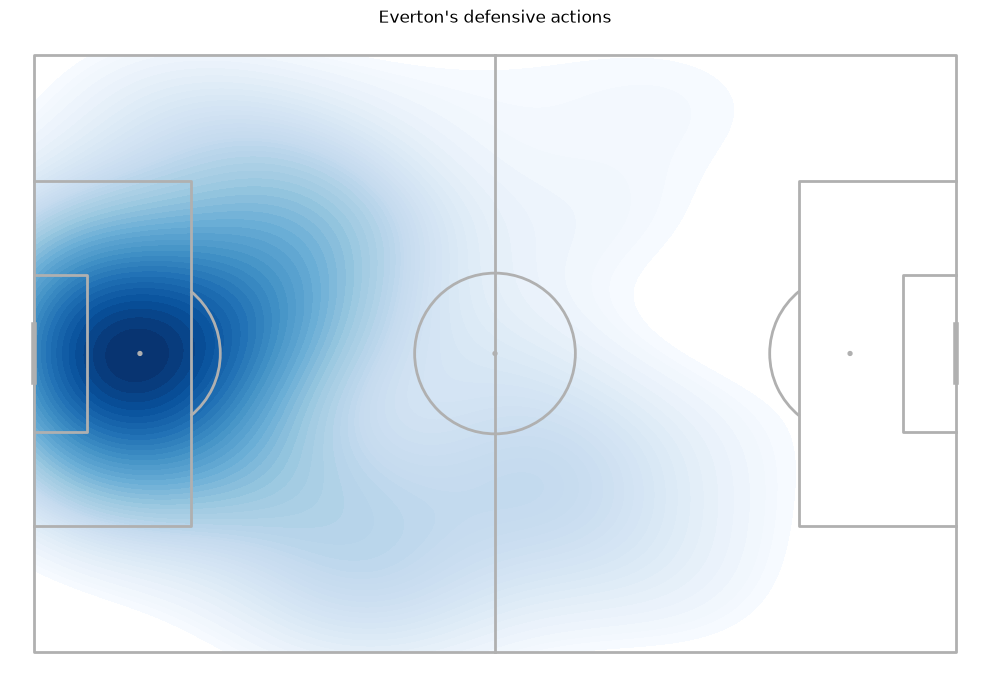

In [42]:
pitch = Pitch(pitch_type="opta", line_zorder=2)
fig, ax = pitch.draw(figsize=(10, 7))

pitch.kdeplot(e_def_actions["x"], e_def_actions["y"], ax=ax,
              fill=True, levels=50, cmap="Blues", thresh=0.05)

ax.set_title("Everton's defensive actions")
plt.show()

In [43]:
e_def_actions["end_x"].notna().sum()

np.int64(30)

**Binning vs density ("fog"):** binning puts each value into a box, and a box gets darker the more values fall into it — good for pass end zones and chance creation, because you can quote the numbers. A density plot shows the overall shape instead, which suits defensive actions.

## 7. Progressive passing

A pass is progressive if it ends at least 25% closer to the opponent's goal than it started (distances in metres, corners and throw-ins excluded).

In [44]:
import numpy as np

events["dist_start"] = np.sqrt(((100 - events["x"]) * 1.05)**2 + ((50 - events["y"]) * 0.68)**2)
events["dist_end"]   = np.sqrt(((100 - events["end_x"]) * 1.05)**2 + ((50 - events["end_y"]) * 0.68)**2)
events["is_progressive"] = events["dist_end"] <= 0.75 * events["dist_start"]
set_piece = events["qualifiers"].str.contains("CornerTaken|ThrowIn")

a_prog = events[
    (events["team"] == "Arsenal")
    & (events["type"] == "Pass")
    & (events["outcome_type"] == "Successful")
    & (events["is_progressive"])
    & (~set_piece)
]
len(a_prog)

lanes = a_prog["end_y"]

prog_right = (lanes < 33.3).sum()
prog_middle = ((lanes >= 33.3) & (lanes <= 66.7)).sum()
prog_left = (lanes > 66.7).sum()

prog_pass = [len(arsenal_passes), len(a_completed), len(a_prog)]
prog_pass


[569, 481, 41]

In [46]:
a_prog[["player", "x", "y", "end_x", "end_y", "dist_start", "dist_end"]].head()

,player,x,y,end_x,end_y,dist_start,dist_end
21,Mikel Merino,42.0,73.9,69.2,92.8,63.031242,43.507682
67,Mikel Merino,67.1,48.7,80.2,38.9,34.556309,22.117785
72,Martin Ødegaard,72.2,16.8,90.4,28.2,36.901651,17.926443
78,Martin Ødegaard,79.6,9.3,80.0,42.0,34.996820,21.693169
86,Mikel Merino,46.2,70.7,93.5,75.6,58.217299,18.698104


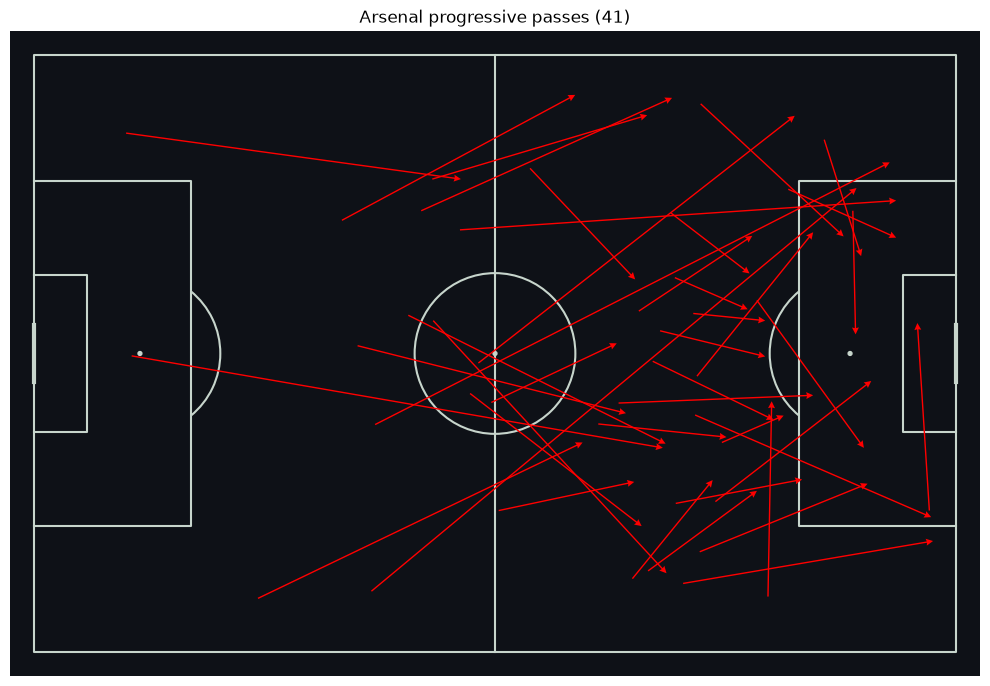

In [47]:
BG = "#0e1117"
LINES = "#c7d5cc"

pitch = Pitch(pitch_type="opta", pitch_color=BG, line_color=LINES, linewidth=1.5, goal_type="line")
fig, ax = pitch.draw(figsize=(10, 7))

pitch.arrows(a_prog["x"], a_prog["y"], a_prog["end_x"], a_prog["end_y"], ax=ax, width=1, headwidth=5, color="red")

ax.set_title(f"Arsenal progressive passes ({len(a_prog)})")

plt.show()

In [48]:
set_piece = events["qualifiers"].str.contains("CornerTaken|ThrowIn")

e_prog = events[
    (events["team"] == "Everton")
    & (events["type"] == "Pass")
    & (events["outcome_type"] == "Successful")
    & (events["is_progressive"])
    & (~set_piece)
]
len(e_prog)

e_lanes = e_prog["end_y"]

e_right = (e_lanes < 33.3).sum()
e_middle = ((e_lanes>= 33.3) & (e_lanes <= 66.7)).sum()
e_left = (e_lanes > 66.7).sum()

routes = [e_right, e_middle, e_left]
routes 

[np.int64(10), np.int64(15), np.int64(8)]

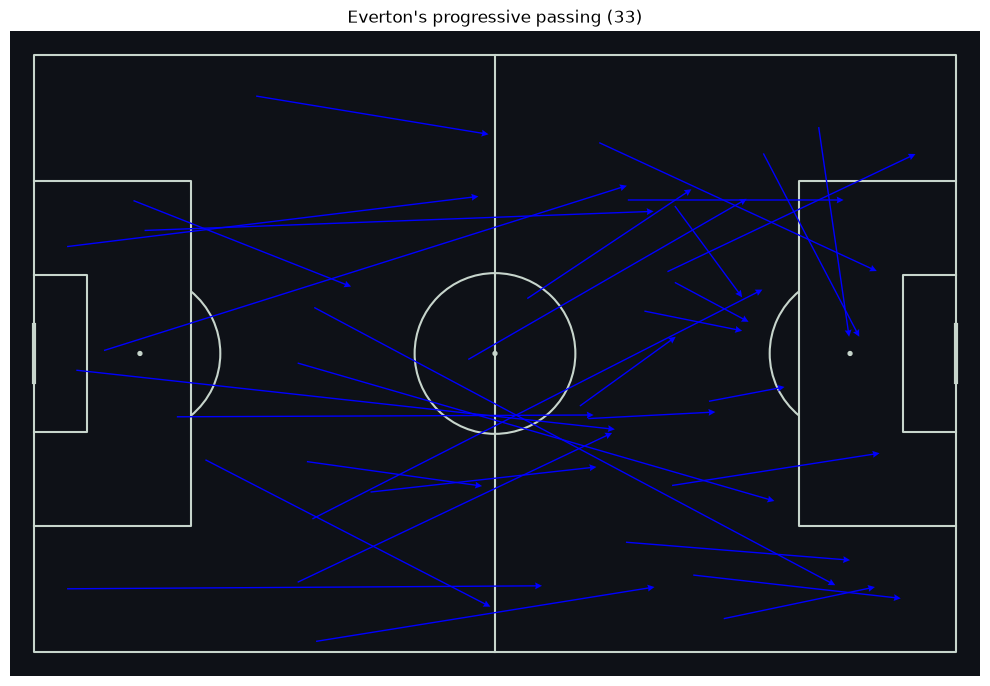

In [49]:
BG = "#0e1117"
LINES = "#c7d5cc"

pitch = Pitch(pitch_type="opta", pitch_color=BG, line_color=LINES, linewidth=1.5, goal_type="line")
fig, ax = pitch.draw(figsize=(10, 7))

pitch.arrows(e_prog["x"], e_prog["y"], e_prog["end_x"], e_prog["end_y"], ax=ax, width=1, headwidth=5, color="blue")

ax.set_title(f"Everton's progressive passing ({len(e_prog)})")

plt.show()

In [52]:
events["ratio"] = events["dist_end"] / events["dist_start"]
events[events["type"] == "Pass"][["player", "dist_start", "dist_end", "ratio", "is_progressive"]].sample(10)

,player,dist_start,dist_end,ratio,is_progressive
1322,Riccardo Calafiori,60.518128,40.647628,0.671660,True
231,Harrison Armstrong,74.596861,62.404062,0.836551,False
153,Merlin Röhl,41.223247,37.068998,0.899226,False
582,Vitalii Mykolenko,41.388891,38.839647,0.938408,False
563,Myles Lewis-Skelly,41.522671,27.824296,0.670099,True
535,Myles Lewis-Skelly,21.995671,7.991057,0.363301,True
720,Myles Lewis-Skelly,38.255408,33.945223,0.887331,False
273,Merlin Röhl,51.701620,50.388842,0.974609,False
835,Jordan Pickford,97.020596,42.074231,0.433663,True
1094,Noni Madueke,27.377189,28.627924,1.045685,False


In [53]:
import ast

labels = []
for text in events[events["type"] == "Pass"]["qualifiers"]:
    for item in ast.literal_eval(text):
        labels.append(item["type"]["displayName"])

pass_labels = pd.Series(labels).value_counts()
print(pass_labels.to_string())

Zone                     970
PassEndX                 970
PassEndY                 970
Length                   970
Angle                    970
Longball                  98
Chipped                   84
Cross                     39
HeadPass                  33
ThrowIn                   29
FreekickTaken             25
LayOff                    23
ShotAssist                22
KeyPass                   22
OppositeRelatedEvent      21
LeftFoot                  21
RightFoot                 18
Offensive                 16
CornerTaken               15
GoalKick                  14
IntentionalAssist         13
KeeperThrow               12
Throughball               11
MissHigh                   7
BigChanceCreated           3
IndirectFreekickTaken      1
RegularPlay                1
IntentionalGoalAssist      1


**Building a metric** means creating a new measure we don't have from the information we already have.

**Why convert to metres?** The Opta pitch is 100 × 100, but a real pitch is about 105 m × 68 m, so the length is multiplied by 1.05 and the width by 0.68 before measuring distances.

## 8. Zone 14 and the half-spaces

Zone 14 is the central area just outside the box; the half-spaces are the channels between the centre and the wings.

In [62]:
in_z14 = a_completed["end_x"].between(66.7, 83) & a_completed["end_y"].between(33.3, 66.7)
a_z14 = a_completed[in_z14]
len(a_z14)

in_hs = a_completed["end_x"].between(66.7, 100) & (
    a_completed["end_y"].between(21.1, 36.8) | a_completed["end_y"].between(63.2, 78.9)
)
a_hs = a_completed[in_hs]
len(a_hs)

a_set_piece = a_completed["qualifiers"].str.contains("CornerTaken|ThrowIn")

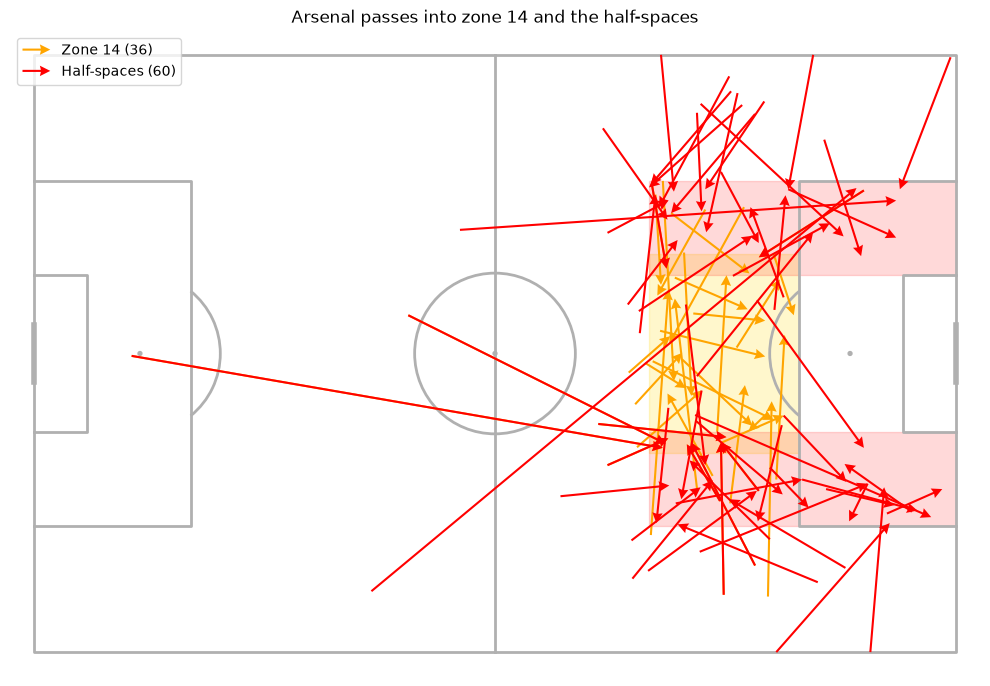

In [68]:
from matplotlib.patches import Rectangle

pitch = Pitch(pitch_type="opta", line_zorder=2)
fig, ax = pitch.draw(figsize=(10, 7))

# shade the zones: Rectangle((bottom-left x, bottom-left y), width, height)
ax.add_patch(Rectangle((66.7, 33.3), 83 - 66.7, 66.7 - 33.3, color="gold", alpha=0.2, zorder=1))
ax.add_patch(Rectangle((66.7, 21.1), 100 - 66.7, 78.9 - 63.2, color="red", alpha=0.15, zorder=1))
ax.add_patch(Rectangle((66.7, 63.2), 100 - 66.7, 36.8 - 21.1, color="red", alpha=0.15, zorder=1))

# arrows on top
pitch.arrows(a_z14["x"], a_z14["y"], a_z14["end_x"], a_z14["end_y"],
             ax=ax, width=1.5, headwidth=5, color="orange", zorder=3, label=f"Zone 14 ({len(a_z14)})")
pitch.arrows(a_hs["x"], a_hs["y"], a_hs["end_x"], a_hs["end_y"],
             ax=ax, width=1.5, headwidth=5, color="red", zorder=3, label=f"Half-spaces ({len(a_hs)})")

ax.legend(loc="upper left")
ax.set_title("Arsenal passes into zone 14 and the half-spaces")
plt.show()

## 9. High turnovers

Ball recoveries, interceptions and won tackles within 40 m of the opponent's goal.

In [85]:
wins = events["type"].isin(["BallRecovery", "Interception"])
won_tackle = (events["type"] == "Tackle") & (events["outcome_type"] == "Successful")
near_goal = events["dist_start"] <= 40

[wins.sum(), won_tackle.sum(), near_goal.sum()]

[np.int64(77), np.int64(17), np.int64(415)]

In [86]:
a_ht = events[(events["team"] == "Arsenal") & (wins | won_tackle) & near_goal]
len(a_ht)

e_ht = events[(events["team"] == "Everton") & (wins | won_tackle) & near_goal]

[len(a_ht), len(e_ht)]



[5, 3]

In [74]:
a_ht[["minute", "player", "type", "outcome_type", "x", "y", "dist_start"]]

,minute,player,type,outcome_type,x,y,dist_start
1120,73,Martin Ødegaard,BallRecovery,Successful,68.4,64.9,34.692504
1161,76,Eberechi Eze,BallRecovery,Successful,71.5,87.9,39.493058
1361,90,Kai Havertz,BallRecovery,Successful,82.3,43.9,19.042272
1396,92,Bruno Guimarães,Tackle,Successful,65.8,37.6,36.886674
1398,92,Bruno Guimarães,BallRecovery,Successful,63.6,41.7,38.634481


In [75]:
e_ht[["minute", "player", "type", "outcome_type", "x", "y", "dist_start"]]

,minute,player,type,outcome_type,x,y,dist_start
173,10,Harrison Armstrong,BallRecovery,Successful,73.6,40.8,28.417177
854,51,Harrison Armstrong,Interception,Successful,72.6,14.5,37.555992
1021,64,Tyrique George,BallRecovery,Successful,76.5,95.5,39.574477


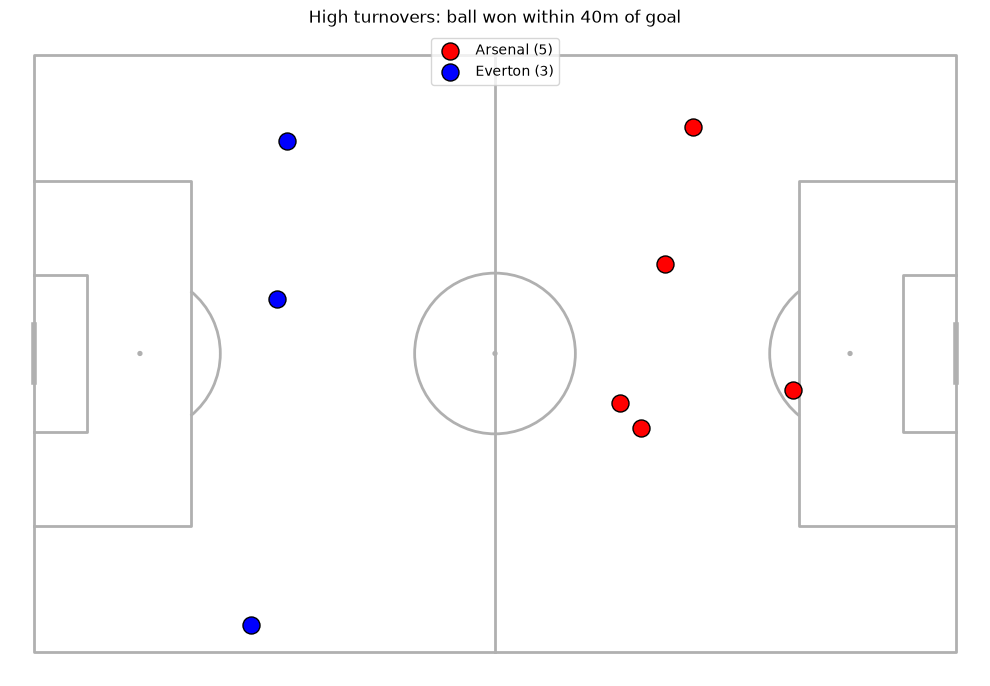

In [87]:
e_ht_flipped = e_ht.copy()
e_ht_flipped["x"] = 100 - e_ht_flipped["x"]
e_ht_flipped["y"] = 100 - e_ht_flipped["y"]                     # the same idea, for y

pitch = Pitch(pitch_type="opta", line_zorder=2)
fig, ax = pitch.draw(figsize=(10, 7))

pitch.scatter(a_ht["x"], a_ht["y"], ax=ax, s=150, color="red",
              edgecolors="black", zorder=3, label=f"Arsenal ({len(a_ht)})")
pitch.scatter(e_ht_flipped["x"], e_ht_flipped["y"], ax=ax, s=150, color="blue",
              edgecolors="black", zorder=3, label=f"Everton ({len(e_ht)})")

ax.legend(loc="upper center")
ax.set_title("High turnovers: ball won within 40m of goal")
plt.show()

Someone has to choose the 40 m cut-off, because there's no neutral line for "high up the pitch". With 30 m it's a lot stricter, so the count would go down.

## 10. Expected threat (xT)

xT gives every zone of the pitch a value for how likely possession there is to lead to a goal. A pass's xT is the value where it ended minus the value where it started.

In [89]:
xt_grid = pd.read_csv(
    "https://raw.githubusercontent.com/mckayjohns/youtube-videos/main/data/xT_Grid.csv",
    header=None
).values
xt_grid.shape

(8, 12)

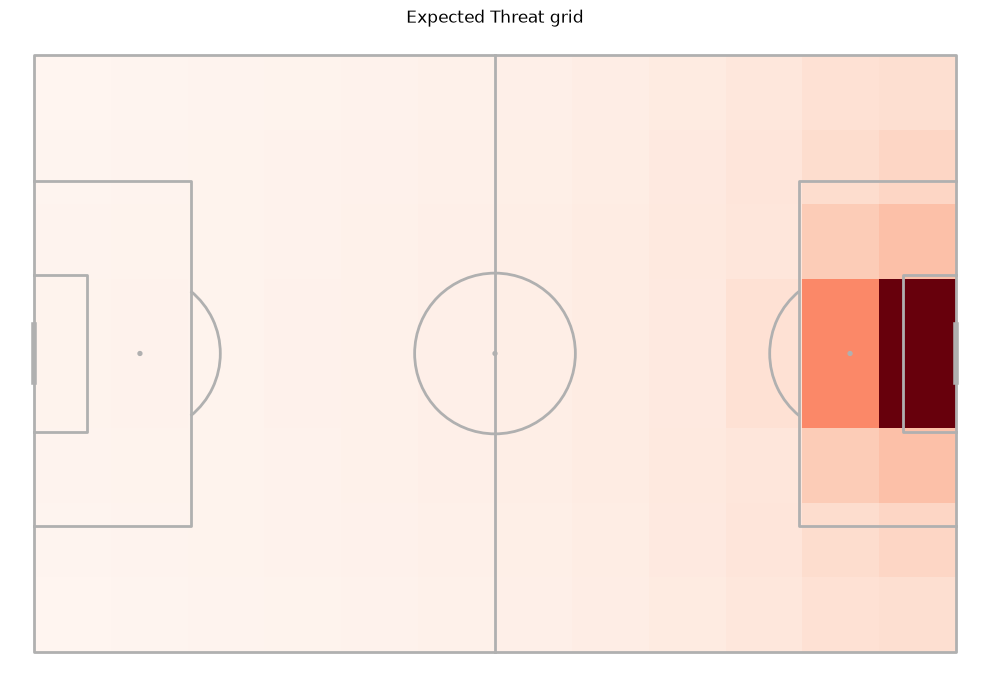

In [91]:
pitch = Pitch(pitch_type="opta", line_zorder=2)
fig, ax = pitch.draw(figsize=(10, 7))

ax.imshow(xt_grid, extent=(0, 100, 0, 100), origin="lower", cmap="Reds",
          zorder=1, aspect=pitch.aspect)

ax.set_title("Expected Threat grid")
plt.show()

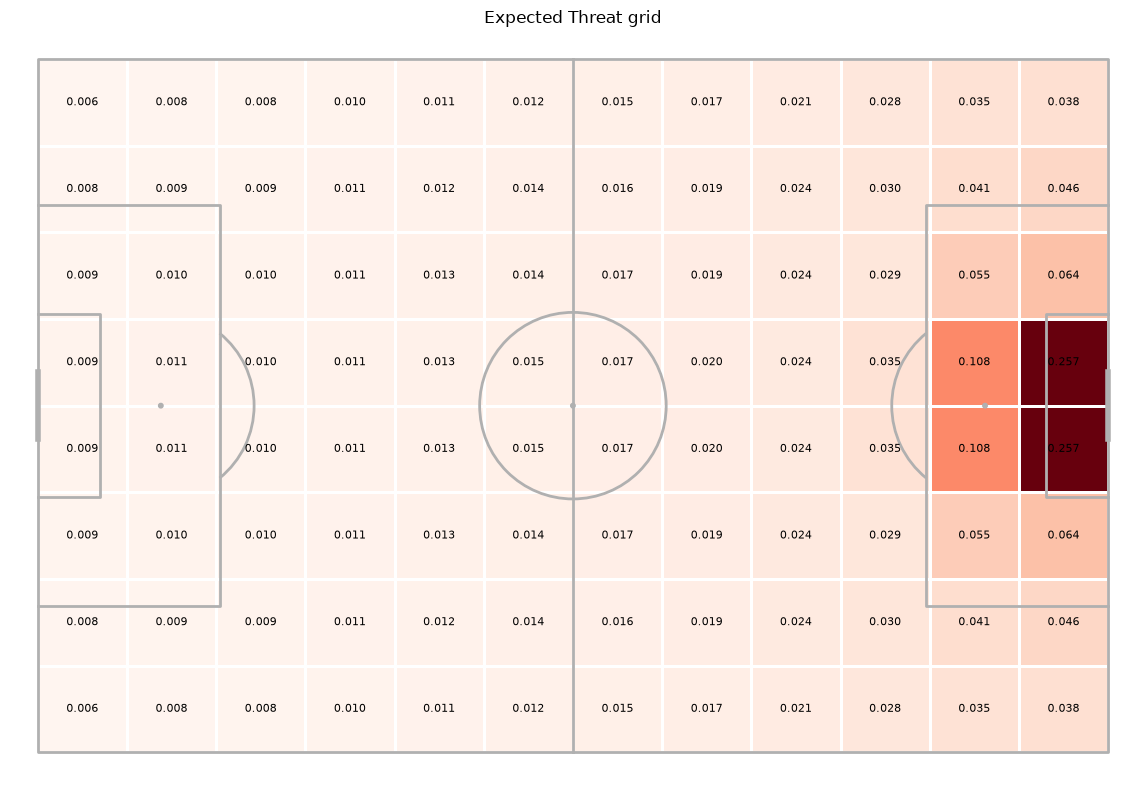

In [92]:
pitch = Pitch(pitch_type="opta", line_zorder=2)
fig, ax = pitch.draw(figsize=(12, 8))

# 1. make an empty 12 x 8 set of boxes
xt_stats = pitch.bin_statistic([50], [50], statistic="count", bins=(12, 8))

# 2. swap the counts for the xT values
xt_stats["statistic"] = xt_grid

# 3. draw and label it, exactly as in Lesson 8
pitch.heatmap(xt_stats, ax=ax, cmap="Reds", edgecolors="white")
pitch.label_heatmap(xt_stats, ax=ax, str_format="{:.3f}", fontsize=8,
                    ha="center", va="center")

ax.set_title("Expected Threat grid")
plt.show()

In [93]:
print(xt_grid.shape)
print(xt_grid.max())

(8, 12)
0.25745362


In [94]:
passes_ok = events[(events["type"] == "Pass") & (events["outcome_type"] == "Successful")].copy()

In [95]:
passes_ok["start_col"] = np.clip((passes_ok["x"] / 100 * 12).astype(int), 0, 11)
passes_ok["start_row"] = np.clip((passes_ok["y"] / 100 * 8).astype(int), 0, 7)
passes_ok["end_col"]   = np.clip((passes_ok["end_x"] / 100 * 12).astype(int), 0, 11)
passes_ok["end_row"]   = np.clip((passes_ok["end_y"] / 100 * 8).astype(int), 0, 7)

start_xt = xt_grid[passes_ok["start_row"], passes_ok["start_col"]]
end_xt = xt_grid[passes_ok["end_row"], passes_ok["end_col"]]

passes_ok["xt"] = np.clip(end_xt - start_xt, 0, None)

In [96]:
passes_ok.loc[a_completed.index[0], ["player", "start_col", "start_row", "end_col", "end_row", "xt"]]

player       Gabriel Magalhães
start_col                    3
start_row                    6
end_col                      4
end_row                      6
xt                    0.001552
Name: 4, dtype: object

In [98]:
passes_ok.groupby("player")["xt"].sum().sort_values(ascending=False)

player
Declan Rice              0.708096
Martin Ødegaard          0.557488
Ben White                0.395085
Myles Lewis-Skelly       0.141046
James Garner             0.138062
Tyrique George           0.128407
Jordan Pickford          0.120754
Harrison Armstrong       0.110829
Gabriel Magalhães        0.098571
Mikel Merino             0.091842
James Tarkowski          0.090227
Bruno Guimarães          0.080502
Eberechi Eze             0.080196
Tyler Dibling            0.072242
Viktor Gyökeres          0.066310
Vitalii Mykolenko        0.065330
Hayden Hackney           0.060636
Kiernan Dewsbury-Hall    0.058571
Ezri Konsa               0.046593
Martín Zubimendi         0.034763
Merlin Röhl              0.031948
Noni Madueke             0.028251
Jake O'Brien             0.019837
David Raya               0.018978
Riccardo Calafiori       0.010490
Kai Havertz              0.004138
Thierno Barry            0.003994
Brennan Johnson          0.003090
Charly Alcaraz           0.001808
Max Dow

In [99]:
(passes_ok[passes_ok["team"] == "Arsenal"]
    .groupby("player")["xt"].sum()
    .sort_values(ascending=False)
    .head(5))

player
Declan Rice           0.708096
Martin Ødegaard       0.557488
Ben White             0.395085
Myles Lewis-Skelly    0.141046
Gabriel Magalhães     0.098571
Name: xt, dtype: float64

In [100]:
a_min = passes_ok[passes_ok["team"] == "Arsenal"].groupby("minute")["xt"].sum()
e_min = passes_ok[passes_ok["team"] == "Everton"].groupby("minute")["xt"].sum()

a_goal_mins = arsenal_shots[arsenal_shots["is_goal"] == True]["minute"]
a_goal_mins

114      6
1069    67
Name: minute, dtype: int64

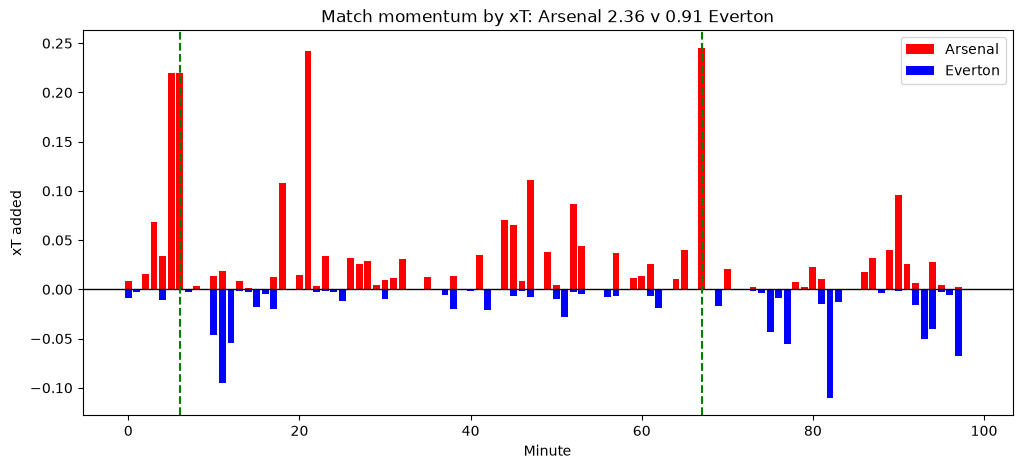

In [102]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.bar(a_min.index, a_min.values, color="red", label="Arsenal")
ax.bar(e_min.index, -e_min.values, color="blue", label="Everton")     # downwards: make it negative
ax.axhline(0, color="black", linewidth=1)

for m in a_goal_mins:
    ax.axvline(m, color="green", linestyle="--", linewidth=1.5)

ax.set_xlabel("Minute")
ax.set_ylabel("xT added")
ax.set_title(f"Match momentum by xT: Arsenal {a_min.sum():.2f} v {e_min.sum():.2f} Everton")
ax.legend()
plt.show()

xT measures how dangerous a pass is. It’s different from a progressive pass because a progressive pass only says yes or no, while xT tell us how dangerous the pass was and where the pass ends - where the pass started tells us how dangerous it was.

In this lesson we used np.clip twice: once to keep the row and column numbers inside the grid, so a pass at exactly x = 100 gives column 11, not column 12, which doesn’t exist and once to turn negative xT (backward or sideways passes that lost threat) into 0, so they don’t count against the team.

## 11. Turning the analysis into functions

Functions have to be defined before they're called. These are the building blocks used in `Match_Report.ipynb`.

In [ ]:
def pass_completion(team):
    team_passes = events[(events["team"] == team) & (events["type"] == "Pass")]
    completed = team_passes[team_passes["outcome_type"] == "Successful"]
    return len(completed) / len(team_passes) * 100

[round(pass_completion("Arsenal"), 1), round(pass_completion("Everton"), 1)]

In [ ]:
def high_turnovers(team, distance=40):
    wins = events["type"].isin(["BallRecovery", "Interception"])
    won_tackle = (events["type"] == "Tackle") & (events["outcome_type"] == "Successful")
    near_goal = events["dist_start"] <= distance
    return events[(events["team"] == team) & (wins | won_tackle) & near_goal]

[len(high_turnovers("Arsenal")), len(high_turnovers("Arsenal", distance=30))]

In [106]:
def draw_shot_map(ax, team, colour, flip=False):
    shots = events[(events["team"] == team) & (events["is_shot"] == True)].copy()
    goals = shots[shots["is_goal"] == True]

    if flip:
        for d in [shots, goals]:
            d["x"] = 100 - d["x"]
            d["y"] = 100 - d["y"]

    pitch = Pitch(pitch_type="opta", line_zorder=2)
    pitch.draw(ax=ax)

    pitch.scatter(shots["x"], shots["y"], ax=ax, s=150, color="none",
                  edgecolors=colour, linewidth=2)
    pitch.scatter(goals["x"], goals["y"], ax=ax, s=300, color=colour,
                  edgecolors="black")

    ax.set_title(f"{team}: {len(shots)} shots, {len(goals)} goals")

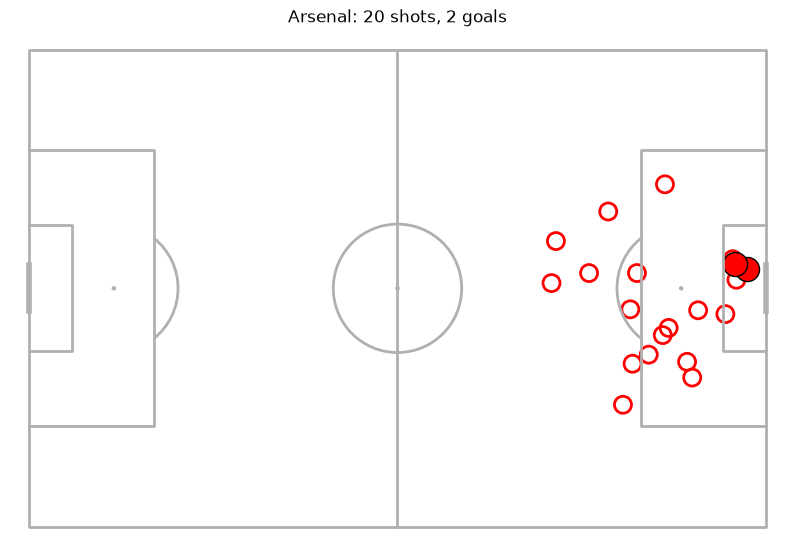

In [107]:
fig, ax = plt.subplots(figsize=(10, 7))
draw_shot_map(ax, "Arsenal", "red")
plt.show()

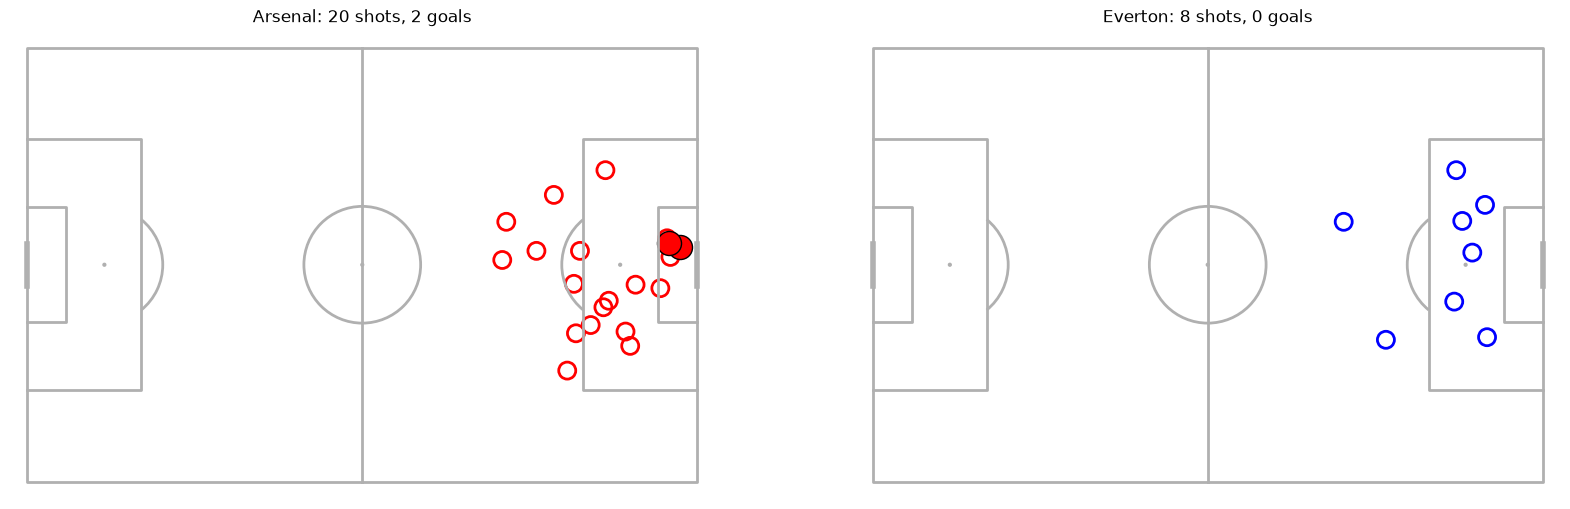

In [108]:
fig, axes = plt.subplots(1, 2, figsize=(20, 7))    # 1 row, 2 columns
draw_shot_map(axes[0], "Arsenal", "red")
draw_shot_map(axes[1], "Everton", "blue")
fig.suptitle("Arsenal 2–0 Everton | Premier League", fontsize=22, fontweight="bold")
plt.show()